# 1. Goal and Methodology

#### The goal of this project is to be able to remotely administer two Rocky Linux servers via a mobile phone
####
#### The methodoly to do this was to configure ssh between the devices and then use ansible to administer both servers at once

# 2. System

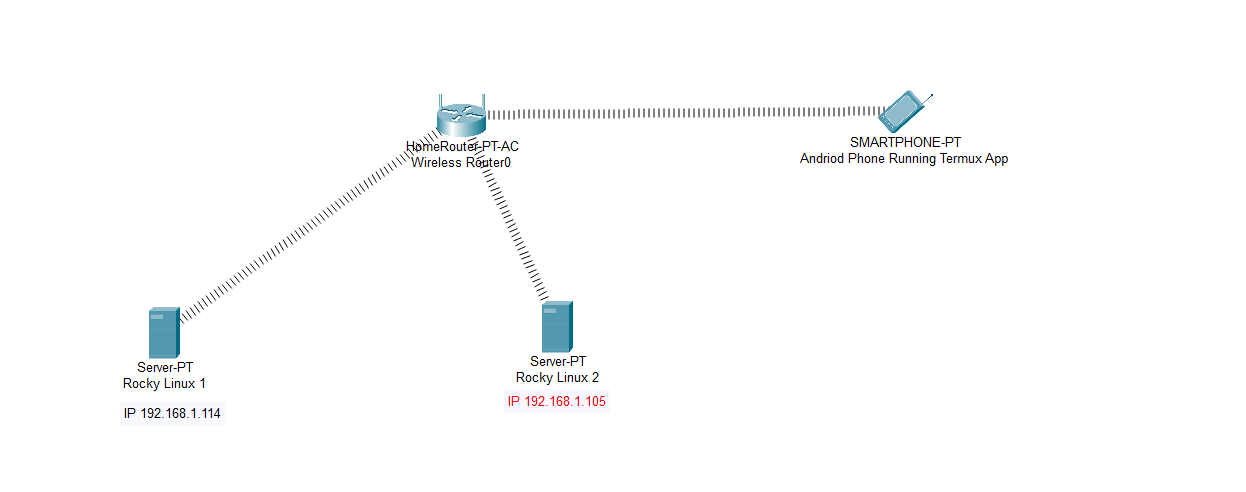

#### This system included an andriod mobile phone using the Termux app as well as two servers using Rocky Linux 10

# 2. Skills and Technologies Demonstrated

| Category | Technologies / Skills |
|---|---|
| Operating systems | Rocky Linux |
| Administration environment | Android, Termux |
| Remote access | SSH, SSH key authentication |
| Configuration management | Ansible |
| Automation | Bash scripting |
| Ansible operations | Inventory, playbooks, ad hoc commands |
| System maintenance | Updates, shutdown operations |

# 2. Configuring Passwordless SSH on Termux connection to Rocky Linux Systems

In [ ]:
pkg install openssh

#### ~/.ssh/config file

In [ ]:
Host rocky1
    Hostname 192.168.1.114
    User: admin
Host rocky2
    Hostname 192.168.1.105
    User: admin

#### ssh key configuration

In [ ]:
ssh-keygen
ssh-copy-id rocky1
ssh-copy-id rocky2

# 3. Installing Ansible on Termux

In [ ]:
pkg search pip
pkg install python -y

In [ ]:
pkg update && pkg install -y python rust openssh openssl libffi libsodium clang cmake build-essential binutils
export CARGO_BUILD_TARGET=aarch4-linux-andriod
export RUSTFLAGS+=" -C llcm-args=-opague-pointers"
pip install --upgrade pip wheel setuptools
pip install cryptography

In [ ]:
pkg install -y python-cryptography python-pynacl
pkg install -y python-cryptography

In [ ]:
SODIUM_INSTALL=system pip install ansible
export ANSIBLE_REMOTE_TEMP=$HOME/.ansible/tmp
export ANSIBLE_LOCAL_TEMP=$HOME/.ansible/tmp
echo "export ANSIBLE_REMOTE_TEMP=$HOME/.ansible/tmp" >> ~/.bashrc
echo "export ANSIBLE_LOCAL_TEMP=$HOME/.ansible/tmp" >> ~/.bashrc

In [ ]:
#verify ansible is installed correctly
ansible --version

# 4. Configuring Ansible

In [ ]:
mkdir ansible-project
vim ~/ansible-project/hosts

#### Hosts file

In [ ]:
[all:vars]
ansible_remote_tmp=$HOME/.ansible/tmp
ansible_local_tmp=$HOME/.ansible/tmp

[linux]
rocky1
rocky2

# 5. Bash Scripts to run basic tasks remotely

### Shutdown Linux Servers

#### shutdown-linux.sh

In [ ]:
#!/usr/bin/env bash

#shutsdown linux vms on pc
#uses ansible combiner with ssh keys

ansible linux -i ansible-project/hosts -m ansible.builtin.command -a "shutdown -h now" -b

#### update-linux.sh

In [ ]:
#!/usr/bin/env bash

#updates linux vms on pc
#uses ansible combiner with ssh keys

ansible-playbook -i ansible-project/hosts update-packages.yml


#### Ansible Playbook update-packages.yml

In [ ]:
---

- name: Update DNF packages asynchronously
  hosts: linux 

  tasks: 

  - name: Ensure all packages are upgraded to the latest version
    dnf:
      name: '*'
      state: latest
    async: 1800
    poll: 10


# 6. Results

#### The linux servers are able to be administered from the remote device
#### Any ad hoc command can be sent to both servers
#### The regular commands of system updates and shutdown can be performed easily with a bash script

# 7. Conclusions

## Technical Experience and Project Outcomes

This project demonstrates my ability to integrate Linux administration, remote access, and automation into a functional multi-server management environment. Using Termux on my mobile device as an Ansible control node, I established remote administrative access to two Rocky Linux servers.

Key technical accomplishments include:

1. **SSH Key-Based Authentication:** Configured SSH key authentication to establish secure connections to both managed servers without repeatedly entering passwords.

2. **Ansible Inventory Management:** Created and configured an inventory containing both Rocky Linux servers, enabling centralized administration from a single control node.

3. **Ansible Playbooks and Ad Hoc Commands:** Developed and executed playbooks and ad hoc commands to perform administrative operations across both servers.

4. **Bash Scripting and Automation:** Developed Bash scripts to automate the execution of Ansible playbooks and ad hoc commands, simplifying routine administrative operations.

5. **Remote System Administration:** Executed routine maintenance operations, including system updates and shutdown commands, across both Rocky Linux servers.

6. **Mobile-Based Administration:** Configured Termux as a mobile administration environment, demonstrating the ability to manage remote Linux infrastructure without relying on a traditional desktop workstation.

### Project Outcome

Successfully established a centralized remote administration environment capable of managing two Rocky Linux servers from a mobile device. Integrated SSH, Ansible, and Bash scripting to streamline routine system administration and maintenance tasks.